<a href="https://colab.research.google.com/github/YafetG3/A04-clustering/blob/main/A04_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Yafet Getachew

**Date:** 10/12/26

In [10]:
# Your Phase 1 solution to the problem goes here.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

In [4]:
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}
for noise, d in datasets.items():
    print(f"noise = {noise:<5}  shape = {d.shape}  groups = {d.group.unique().tolist()}")

noise = 0.125  shape = (150, 3)  groups = ['a', 'b', 'c']
noise = 0.25   shape = (150, 3)  groups = ['a', 'b', 'c']
noise = 0.5    shape = (150, 3)  groups = ['a', 'b', 'c']
noise = 1.0    shape = (150, 3)  groups = ['a', 'b', 'c']
noise = 2.0    shape = (150, 3)  groups = ['a', 'b', 'c']


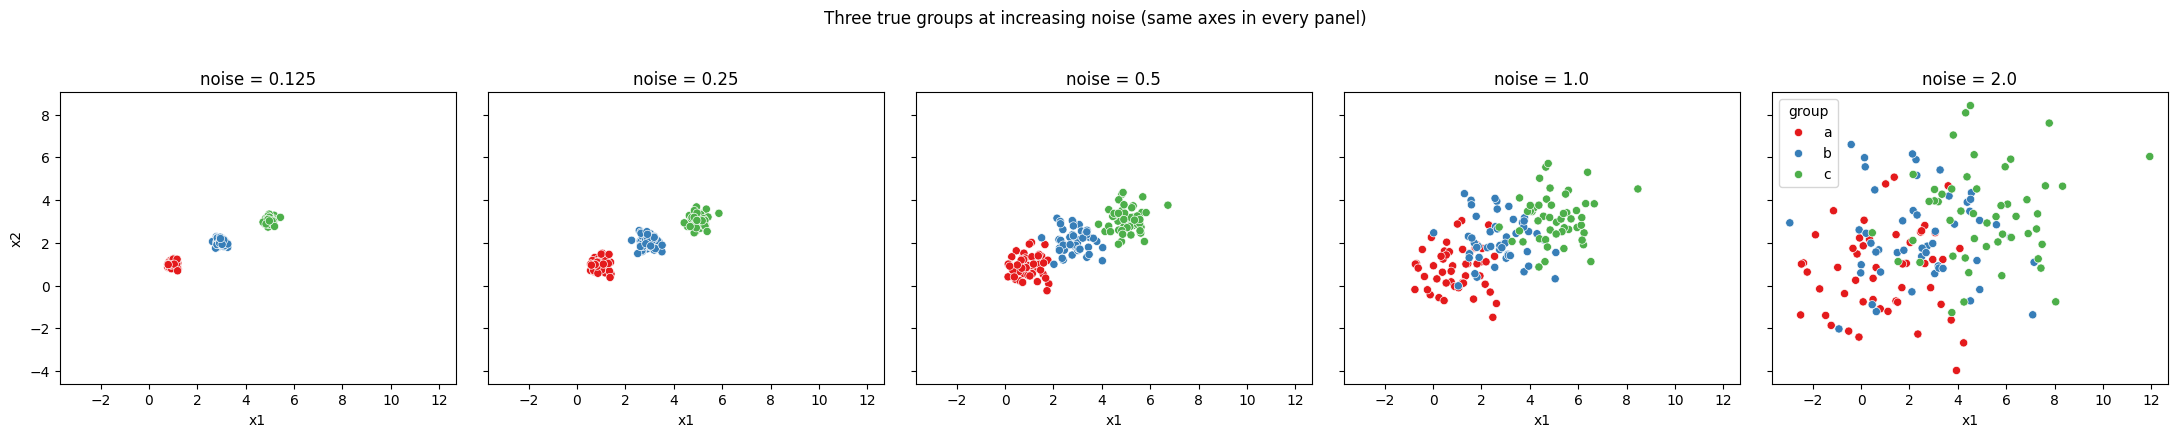

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, datasets.items()):
    sns.scatterplot(data=d, x='x1', y='x2', hue='group', palette='Set1', s=35, ax=ax, legend=(noise == 2.0))
    ax.set_title(f"noise = {noise}")
axes[-1].legend(title='group', loc='upper left')
plt.suptitle("Three true groups at increasing noise (same axes in every panel)", y=1.03)
plt.tight_layout()
plt.show()

- 0.125 and 0.25: three tight, clearly separated clusters
- 0.5: the blobs/clusters are wider and a/b and b/c touch at the edges, but the three groups are still easy to see and are distinct
- 1.0: A lot more overlap there is a rough left-to-right order of between the groups but no clean boundaries that show the end/beginning
- 2.0: the colors are thoroughly mixed and the data look like one big cluter all over the grid

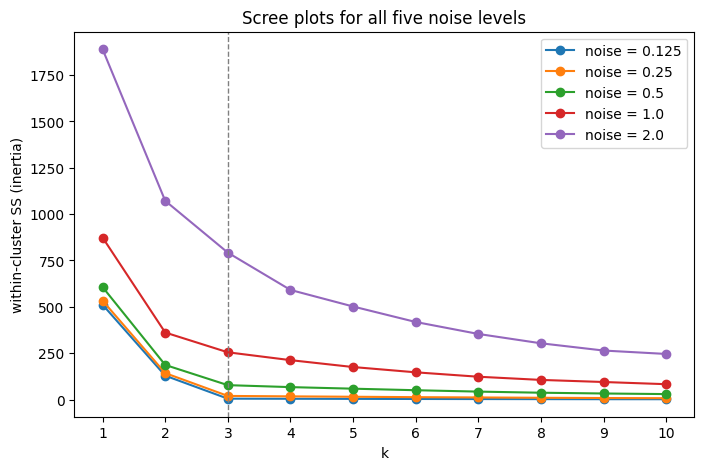

In [11]:
ks = range(1, 11)
inertia = {}
for noise, d in datasets.items():
    X = d[['x1', 'x2']].values
    inertia[noise] = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

# all five on one canvas
fig, ax = plt.subplots(figsize=(8, 5))
for noise, vals in inertia.items():
    ax.plot(list(ks), vals, marker='o', label=f"noise = {noise}")
ax.axvline(3, color='gray', ls='--', lw=1)   # true k = 3
ax.set_xlabel("k")
ax.set_ylabel("within-cluster SS (inertia)")
ax.set_xticks(list(ks))
ax.set_title("Scree plots for all five noise levels")
ax.legend()
plt.show()

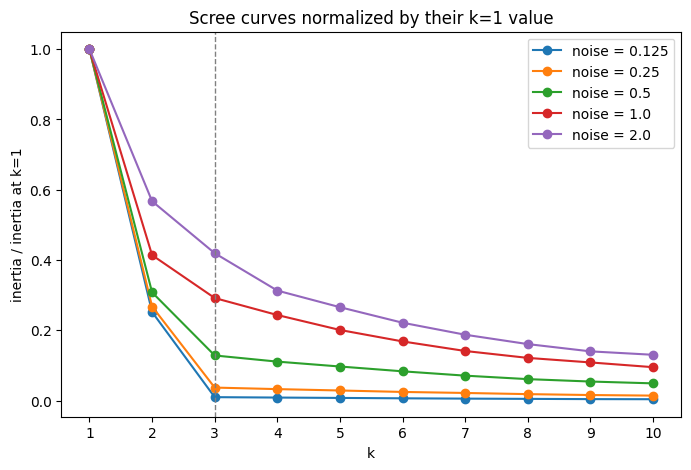

,drop 1->2,drop 2->3,drop 3->4
noise=0.125,0.748,0.962,0.118
noise=0.25,0.732,0.862,0.118
noise=0.5,0.692,0.583,0.137
noise=1.0,0.586,0.295,0.166
noise=2.0,0.433,0.261,0.254


In [12]:
# rescaled so k=1 equals 1.0
fig, ax = plt.subplots(figsize=(8, 5))
for noise, vals in inertia.items():
    ax.plot(list(ks), np.array(vals) / vals[0], marker='o', label=f"noise = {noise}")
ax.axvline(3, color='gray', ls='--', lw=1)
ax.set_xlabel("k"); ax.set_ylabel("inertia / inertia at k=1"); ax.set_xticks(list(ks))
ax.set_title("Scree curves normalized by their k=1 value")
ax.legend(); plt.show()

# Inertia removed as k decreases
summary = pd.DataFrame({
    'drop 1->2': [1 - v[1]/v[0] for v in inertia.values()],
    'drop 2->3': [1 - v[2]/v[1] for v in inertia.values()],
    'drop 3->4': [1 - v[3]/v[2] for v in inertia.values()],
}, index=[f"noise={n}" for n in inertia]).round(3)
display(summary)

## noise + elbow + choosing k
- As noise increases, the elbow is harder to make out and it becomes harder to select k definitively. At low noise (0.125 and 0.25) there is a sharp elbow at k = 3 as inertia falls by 96% and 86% going from k = 2 to k = 3, but by only about 12% going from k = 3 to k = 4. At noise 0.5 the elbow is still visible but less noticable (58% drop, then 14%). At noise 1.0 the curve is basically smooth (30%, then 17%), and the largest drop is from k = 1 to k = 2. At noise 2.0 there is no elbow (26%, then 25%).

- The vertical axis also changes with noise as Inertia at k = 3 rises from about 5 at noise 0.125 to about 800 at noise 2.0. Additionally I can choose k = 3 at low noise and defend it at 0.5. At 1.0 you could reasonably choose k = 2 or 3, and at 2.0 the scree plot cannot identify k.

## intuition of the elbow
- Inertia always decreases as k increases, and it reaches 0 when every point is its own cluster. So you can't just pick the k with the smallest inertia, instead you have to look for where adding a cluster stops helping much.

- In the simulation, when k is below the true value of 3, each additional center separates groups that were forced together, which removes a lot of squared error. At noise 0.25, inertia falls from about 143 at k = 2 to about 20 at k = 3. When k is above 3, each extra center gains only a small amount (about 12% per step), the same as splitting any cloud of random points.

- How clear the elbow is depends on how far apart the groups are relative to their spread, meaning, that when noise is large, splitting a real group saves barely more than splitting a blob, so the curve becomes smooth and the elbow disappears.

### Q2

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [16]:
url = "https://raw.githubusercontent.com/sds3001/A04-clustering/main/data/SIPRI%20Military%20Expenditure%20Database.csv"
df = pd.read_csv(url)
df = df[df["Year"] == 2020].dropna()
print(df.shape)

(148, 7)


- No further cleaning is required: there are no duplicate countries, all four analysis variables are numeric, and none has zero or negative values.

In [17]:
S, P = "Spending (2020 USD)", "Spending per Capita"
G, C = "Percent of Government Spending", "Percent of GDP"

def maxmin(s):
    return (s - s.min()) / (s.max() - s.min())

def scree(X):
    sse = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in range(1, 11)]
    plt.plot(range(1, 11), sse, marker="o")
    plt.xlabel("k"); plt.ylabel("total sum of squared error")
    plt.show()

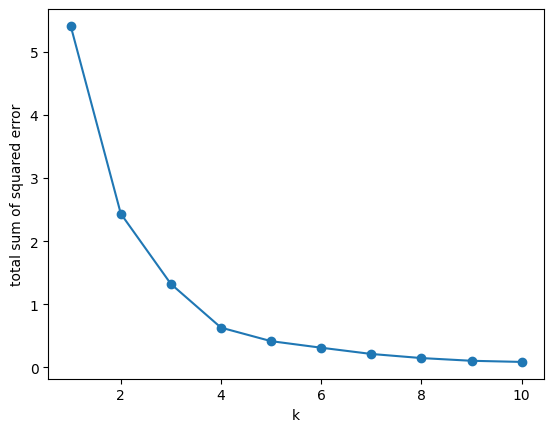

In [18]:
dfA = df.copy()
XA = dfA[[S, P]].apply(maxmin)
scree(XA)

## Choosing K
- The scree plot drops steeply up to k = 4 (5.41, 2.44, 1.32, 0.63) and then flattens (0.42, 0.31, ...), so I chose k = 4.

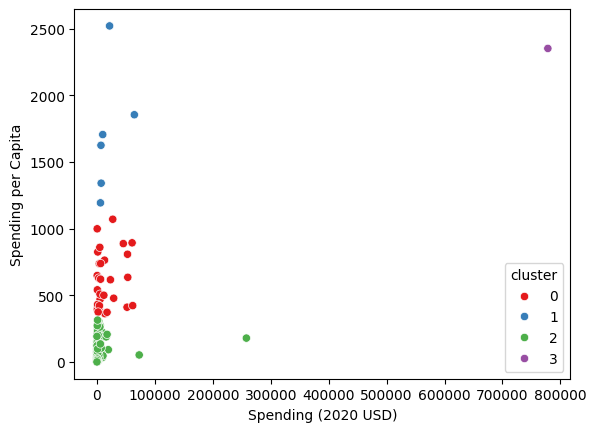

In [19]:
dfA["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(XA)
sns.scatterplot(data=dfA, x=S, y=P, hue="cluster", palette="Set1")
plt.show()

In [20]:
dfA[dfA["Country"] == "United States of America"]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3


### Where is the US
- It is alone in its own cluster, in the far upper-right corner of the scatterplot. It spends about three times as much as the next country (China) and has one of the highest per-capita figures.

## patterns
- Clusters follow wealth and alliances. Cluster 0 is mostly wealthy NATO and US-allied countries plus Russia, cluster 1 is small rich or conflict-exposed states, and cluster 2 is mostly lower and middle income countries, although one oddball is China, which is in cluster 2. After normalization its per-capita spending ($179) is low, and the US sets the scale of the spending axis.

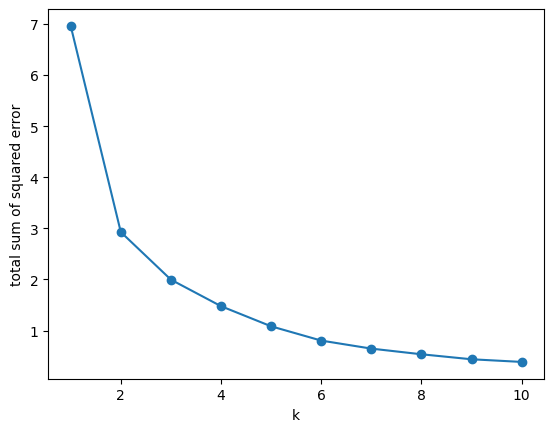

In [21]:
dfB = df.copy()
XB = dfB[[G, C]].apply(maxmin)
scree(XB)

## Choosing k
- The scree plot bends at about k = 3 (6.96, 2.93, 2.00, 1.48), though less sharply than in part 2, so I chose k = 3.

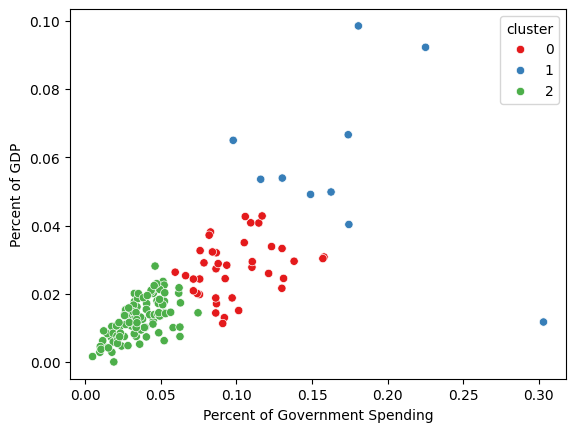

In [22]:
dfB["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(XB)
sns.scatterplot(data=dfB, x=G, y=C, hue="cluster", palette="Set1")
plt.show()

In [23]:
dfB.groupby("cluster")[[G, C]].describe()

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

- The two variables are positively related, so the points form a diagonal band, and the clusters are low, medium and high slices along it.

The US is in the middle cluster --> not unusual.

##Compare w/ Part 2
- Part 2 groups countries by dollars and spending per person, while part 3 groups them by share of the budget and the economy, so the results look very different. The US goes from being such an outlier to looking like a regular member in the middle cluster. Rich European countries, are grouped as high spenders p/person relative to their econmoy/budget and even poor countries moving into the middle cluster in part 3

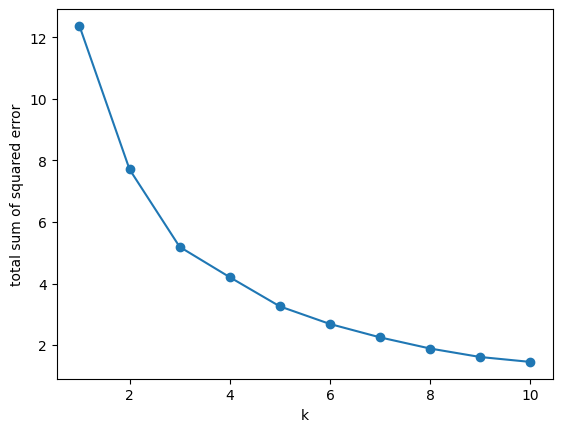

In [24]:
dfC = df.copy()
XC = dfC[[S, P, G, C]].apply(maxmin)
scree(XC)

## Choosing k
- The scree curve is smooth (12.4, 7.7, 5.2, 4.2, 3.3, ...) with a gentle bend around k = 4, so k = 4 is a judgment call (3 or 5 would also be defensible).

In [25]:
dfC["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(XC)
dfC.groupby("cluster")[[S, P, G, C]].describe()

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      30.0    9073.543709   18135.032885   163.926877   
3                      26.0   15330.618681   18923.469359   405.790494   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         522.737081   1663.090134   8646.648849   72937.064048   
3        3176.345598   5857.060906  21818.934764   60675.039625   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      86.0    70.290644  ...                       0.053006   
1                       6.0  1875.150751  ...                       0.164503   
2                      30.0   215.920971  ...                       0.136403   
3                      26.0   612.677541  ...                       0.044645   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
3        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   

                                       
              50%       75%       max  
cluster                                
0        0.012532  0.016783  0.026340  
1        0.059257  0.085398  0.098470  
2        0.032148  0.040637  0.066600  
3        0.015324  0.020431  0.028132  

[4 rows x 32 columns]

## comparing with parts 2 and 3
- This result combines the two earlier ones and separates "rich but low burden" countries (cluster 3) from "less rich but heavily militarized" ones (cluster 2), which neither part 2 nor part 3 could do alone. The US is no longer alone, because two of the four variables now measure burden and it lands with the Gulf states and Israel.

## Did k-means find useful patterns
- Yes, partly. It showed that the scale of military spending and the burden it places on a country are different things. The four-variable clustering combined both into a sensible grouping: the US as an outlier in dollars, rich allies with low burden, high-burden regional-security states, and a large group of low spenders.
- However, there are limits as k-means uses distance, so outliers and scaling matter a lot. The US squashes everyone else after max-min scaling, which is why China ends up with much smaller spenders in part 2. Picking k is is a lot harder when the elbow is gentle, and the clusters describe groups but don't explain why countries spend what they do. Finally, the 25 countries dropped for missing data could've resulted in pattersn that may hvve been missed.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 551b89984c1f948a3c2a31436588ceac9aa7dbaa
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [9]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]